<a href="https://colab.research.google.com/github/petricksoares/-devops-trabalho/blob/main/petrick_pratica_alunos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Árvores, Random Forest e Boosting

**Problema:** prever quem sobreviveu ao naufrágio do **Titanic** (dataset clássico do Kaggle).

Comece com `Ambiente de execução → Executar tudo` para carregar os dados.

## 0. Preparação (já pronta, só rode)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(url)

# Limpeza e encoding (conteúdo da Unidade II)
df = df[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]].copy()
df["age"] = df["age"].fillna(df["age"].median())
df["embarked"] = df["embarked"].fillna("S")
df["sex"] = df["sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["embarked"], dtype=int)

X = df.drop(columns="survived")
y = df["survived"]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print(f"{len(df)} passageiros | {y.mean():.0%} sobreviveram")
df.head()

891 passageiros | 38% sobreviveram


,survived,pclass,sex,age,sibsp,parch,fare,embarked_C,embarked_Q,embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


| Coluna | Significado |
|---|---|
| `pclass` | classe do bilhete (1 = primeira, 3 = terceira) |
| `sex` | 0 = homem, 1 = mulher |
| `age` | idade |
| `sibsp` / `parch` | nº de irmãos/cônjuges e de pais/filhos a bordo |
| `fare` | valor pago na passagem |
| `embarked_*` | porto de embarque (C, Q, S) |

In [2]:
# Função de avaliação: validação cruzada de 5 partes (igual à demo).
# Mostra a acurácia no treino e nos dados que o modelo NÃO viu (validação).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados = []

def avaliar(nome, modelo):
    r = cross_validate(modelo, X, y, cv=cv, return_train_score=True, n_jobs=-1)
    treino, valid = r["train_score"].mean(), r["test_score"].mean()
    resultados.append({"Modelo": nome, "Treino": treino, "Validação": valid})
    print(f"{nome:<40} treino: {treino:.1%}   validação: {valid:.1%}")

---
## Etapa 1 — Árvore de Decisão

> **Lembrete:** a árvore faz perguntas em sequência (ex.: *"sex ≤ 0,5?"*).
> Quanto mais profunda, mais ela acerta o treino, mas a partir de certo ponto ela **decora** e piora nos dados novos (overfitting).
> O hiperparâmetro que controla isso é o `max_depth`.

**1.1** Rode a árvore sem limite de profundidade:

In [3]:
avaliar("Árvore sem limite", DecisionTreeClassifier(random_state=42))

Árvore sem limite                        treino: 98.2%   validação: 78.9%


**1.2** Agora teste três profundidades. Substitua os `___` por `2`, `4` e `8`:

In [5]:
# avaliar("Árvore max_depth=2", DecisionTreeClassifier(max_depth=___, random_state=42))
# avaliar("Árvore max_depth=4", DecisionTreeClassifier(max_depth=___, random_state=42))
# avaliar("Árvore max_depth=8", DecisionTreeClassifier(max_depth=___, random_state=42))

avaliar("Árvore max_depth=2", DecisionTreeClassifier(max_depth=2, random_state=42))
avaliar("Árvore max_depth=4", DecisionTreeClassifier(max_depth=4, random_state=42))
avaliar("Árvore max_depth=8", DecisionTreeClassifier(max_depth=8, random_state=42))

Árvore max_depth=2                       treino: 79.8%   validação: 77.7%
Árvore max_depth=4                       treino: 83.9%   validação: 81.8%
Árvore max_depth=8                       treino: 90.3%   validação: 82.9%


**1.3** Desenhe uma árvore pequena, treinada só com os dados de treino:

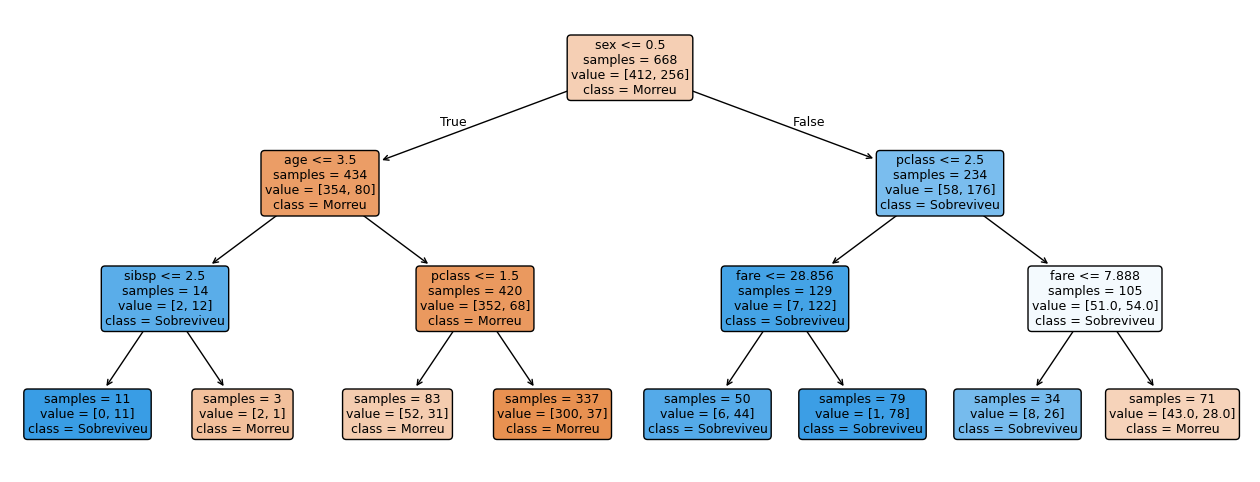

In [7]:
arvore = DecisionTreeClassifier(max_depth=3, random_state=42)
arvore.fit(X_treino, y_treino)

plt.figure(figsize=(16, 6))
plot_tree(arvore, feature_names=X.columns, class_names=["Morreu", "Sobreviveu"],
          filled=True, rounded=True, impurity=False, fontsize=9)
plt.show()

**1.4 Qual pergunta a árvore fez primeiro? Por que você acha que ela escolheu essa?**

*Sua resposta:* A primeira pergunta que a árvore fez foi para saber se o passageiro era um homem ou uma mulher. Como sex está 0 para homem e 1 para mulher, o ramo "True" ficou com homens e "False" com mulheres.
Acredito que ela começou por essa pergunta porque o sexo foi a variável que melhor separou quem sobreviveu de quem morreu. A árvore escolhe a divisão que mais reduz a impureza dos grupos, e os números mostram isso: entre os homens (434) cerca de 18% sobreviveram, enquanto entre as mulheres (234) cerca de 75% sobreviveram. Com uma única pergunta, ela já criou dois grupos bem mais "puros" do que o conjunto original, em que 38% sobreviveram.

**1.5 Qual profundidade você escolheria? Compare treino × validação para justificar.**

*Sua resposta:* Eu escolheria `max_depth=4`. Com profundidade 2, treino e validação ficaram baixos (79,8% e 77,7%), o que indica que a árvore era simples demais. Com profundidade 4, os dois subiram (83,9% e 81,8%) e a diferença continuou pequena, cerca de 2 pontos. Já com profundidade 8, o treino foi para 90,3% e a validação para 82,9%, uma diferença de 7,4 pontos. A validação melhorou só 1,1 ponto em relação à profundidade 4, enquanto o treino subiu 6,4, então o ganho é pequeno e a árvore já está começando a decorar os dados. A profundidade 4 me parece o melhor equilíbrio entre acerto e capacidade de generalizar.

<details><summary>Extra para quem terminou</summary>

Use `arvore.predict(...)` para prever a sobrevivência de um passageiro inventado por você.
Monte um `pd.DataFrame` com **as mesmas colunas** de `X` (dica: `X.columns`).
</details>

---
## Etapa 2 — Random Forest

> **Lembrete:** a Random Forest treina **muitas árvores diferentes** (cada uma vê uma amostra sorteada dos dados
> e um sorteio de colunas) e decide pelo **voto da maioria**. Isso corrige a instabilidade de uma árvore só.
> Hiperparâmetros principais: `n_estimators` (nº de árvores) e `max_depth`.
> Mais árvores não causam overfitting, só deixam o treino mais lento.

**2.1** Complete a linha do modelo: uma `RandomForestClassifier` com 100 árvores.
Dica: compare com a linha da árvore; o nome do parâmetro é `n_estimators`.

In [8]:
# avaliar("RF 100 árvores", ___)
avaliar("RF 100 árvores", RandomForestClassifier(n_estimators=100, random_state=42))

RF 100 árvores                           treino: 98.2%   validação: 82.5%


**2.2** Experimente combinações. Altere os valores e rode quantas vezes quiser (cada rodada entra na tabela):

In [9]:
n = 100          # nº de árvores. Experimente: 10, 100, 300
prof = 5         # profundidade máxima. Experimente: None, 5, 8

avaliar(f"RF {n} árvores, max_depth={prof}",
        RandomForestClassifier(n_estimators=n, max_depth=prof, random_state=42))

RF 100 árvores, max_depth=5              treino: 85.5%   validação: 83.5%


**2.3** Quais variáveis a floresta mais usou?

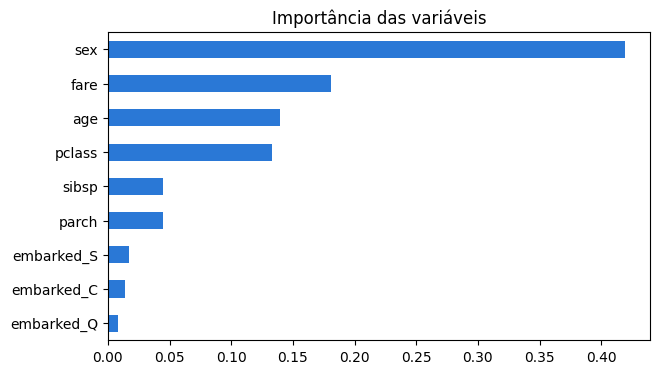

In [11]:
# rf = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
# rf.fit(X_treino, y_treino)

# importancia = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
# importancia.plot.barh(color="#2a78d6", figsize=(7, 4), title="Importância das variáveis")
# plt.show()

rf = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
rf.fit(X_treino, y_treino)

importancia = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importancia.plot.barh(color="#2a78d6", figsize=(7, 4), title="Importância das variáveis")
plt.show()

# Os dados que mais foram usados foram: sex, fare, age e pclass.

**2.4 Quais são as 3 variáveis mais importantes? Isso faz sentido historicamente?**

*Sua resposta:* As três mais importantes foram sex, fare e age. Faz sentido porque a regra era de mulheres e crianças primeiro, isso explica o peso de sex e age, e o fare reflete a classe social, já que quem pagava mais ficava na 1ª classe e tinha mais chance de chegar aos botes.

**2.5 A Random Forest foi melhor que a sua melhor árvore? Por quanto?**

*Sua resposta:* Sim por pouco. A melhor árvore (max_depth=8) teve validação de 82,9%, e a melhor Random Forest (100 árvores, max_depth=5) teve 83,5%, uma vantagem de cerca de 0,6 ponto percentual. A floresta também decorou menos o treino: a diferença entre treino e validação foi de 2 pontos, contra 7,4 da árvore.

---
## Etapa 3 — Gradient Boosting

> **Lembrete:** no boosting, as árvores são treinadas **em fila**: cada nova árvore corrige os erros das anteriores.
> O `learning_rate` controla o tamanho de cada correção. Taxa alta demais → o modelo decora o treino.
> Diferente da Random Forest, **boosting pode sofrer overfitting** e precisa de ajuste.

**3.1** Complete o modelo com `GradientBoostingClassifier` usando `learning_rate=0.1`:

In [12]:
# avaliar("Boosting lr=0.1", ___)
avaliar("Boosting lr=0.1", GradientBoostingClassifier(learning_rate=0.1, random_state=42))

Boosting lr=0.1                          treino: 90.1%   validação: 82.7%


**3.2** Teste uma taxa baixa e uma alta. Substitua por `0.01` e `1.0`:

In [13]:
# avaliar("Boosting lr=0.01", GradientBoostingClassifier(learning_rate=___, random_state=42))
# avaliar("Boosting lr=1.0",  GradientBoostingClassifier(learning_rate=___, random_state=42))

avaliar("Boosting lr=0.01", GradientBoostingClassifier(learning_rate=0.01, random_state=42))
avaliar("Boosting lr=1.0",  GradientBoostingClassifier(learning_rate=1.0, random_state=42))

Boosting lr=0.01                         treino: 83.5%   validação: 81.5%
Boosting lr=1.0                          treino: 98.2%   validação: 81.0%


**3.3 O que aconteceu com o treino e a validação quando a taxa foi para 1.0?**

*Sua resposta:* Com `lr=1.0`, o treino subiu para 98,2%, mas a validação caiu para 81,0%, a menor das três taxas. A diferença entre as colunas chegou a 17,2 pontos, contra 7,4 com `lr=0.1`. Isso é overfitting: cada árvore aplica a correção inteira, o modelo se ajusta demais aos erros do treino e acaba decorando os dados, perdendo capacidade de generalizar.

---
## Desafio: Seu melhor modelo

Escolha **qualquer** modelo e hiperparâmetros vistos hoje e tente a maior acurácia de **validação**.
Rode quantas vezes quiser. Ideias: `max_depth`, `n_estimators`, `learning_rate`, `min_samples_leaf`.

In [15]:
avaliar("Meu melhor modelo", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=3, random_state=42))

#Testando várias combinações
for prof in [4, 5, 6]:
    for folha in [1, 3, 5, 10]:
        avaliar(f"RF 300 árvores, max_depth={prof}, min_samples_leaf={folha}",
                RandomForestClassifier(n_estimators=300, max_depth=prof,
                                       min_samples_leaf=folha, random_state=42))

# Vendo o ranking do melhor
pd.DataFrame(resultados).sort_values("Validação", ascending=False).head(5)

Meu melhor modelo                        treino: 86.1%   validação: 82.8%
RF 300 árvores, max_depth=4, min_samples_leaf=1 treino: 84.6%   validação: 82.9%
RF 300 árvores, max_depth=4, min_samples_leaf=3 treino: 84.3%   validação: 83.1%
RF 300 árvores, max_depth=4, min_samples_leaf=5 treino: 84.4%   validação: 82.5%
RF 300 árvores, max_depth=4, min_samples_leaf=10 treino: 83.6%   validação: 82.5%
RF 300 árvores, max_depth=5, min_samples_leaf=1 treino: 85.5%   validação: 83.1%
RF 300 árvores, max_depth=5, min_samples_leaf=3 treino: 85.0%   validação: 83.3%
RF 300 árvores, max_depth=5, min_samples_leaf=5 treino: 84.9%   validação: 83.3%
RF 300 árvores, max_depth=5, min_samples_leaf=10 treino: 84.0%   validação: 82.5%
RF 300 árvores, max_depth=6, min_samples_leaf=1 treino: 87.3%   validação: 83.3%
RF 300 árvores, max_depth=6, min_samples_leaf=3 treino: 86.1%   validação: 82.8%
RF 300 árvores, max_depth=6, min_samples_leaf=5 treino: 85.4%   validação: 83.2%
RF 300 árvores, max_depth=6, min_

,Modelo,Treino,Validação
8,"RF 100 árvores, max_depth=5",0.855218,0.834995
19,"RF 300 árvores, max_depth=5, min_samples_leaf=3",0.850448,0.832747
20,"RF 300 árvores, max_depth=5, min_samples_leaf=5",0.848764,0.832741
22,"RF 300 árvores, max_depth=6, min_samples_leaf=1",0.872613,0.832741
24,"RF 300 árvores, max_depth=6, min_samples_leaf=5",0.854377,0.831618


<details><summary> Extra: XGBoost</summary>

O XGBoost é a versão de boosting mais usada na indústria e já vem instalado no Colab.
A interface é a mesma do scikit-learn:

```python
from xgboost import XGBClassifier
avaliar("XGBoost", XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3))
```
</details>

---
## Seus resultados

Rode a célula abaixo para ver todos os modelos que você avaliou, do melhor para o pior:

In [16]:
tabela = (pd.DataFrame(resultados)
          .drop_duplicates("Modelo", keep="last")
          .sort_values("Validação", ascending=False)
          .reset_index(drop=True))
tabela.style.format({"Treino": "{:.1%}", "Validação": "{:.1%}"})

,Modelo,Treino,Validação
0,"RF 100 árvores, max_depth=5",85.5%,83.5%
1,"RF 300 árvores, max_depth=5, min_samples_leaf=3",85.0%,83.3%
2,"RF 300 árvores, max_depth=5, min_samples_leaf=5",84.9%,83.3%
3,"RF 300 árvores, max_depth=6, min_samples_leaf=1",87.3%,83.3%
4,"RF 300 árvores, max_depth=6, min_samples_leaf=5",85.4%,83.2%
5,"RF 300 árvores, max_depth=4, min_samples_leaf=3",84.3%,83.1%
6,"RF 300 árvores, max_depth=5, min_samples_leaf=1",85.5%,83.1%
7,Árvore max_depth=8,90.3%,82.9%
8,"RF 300 árvores, max_depth=4, min_samples_leaf=1",84.6%,82.9%
9,Meu melhor modelo,86.1%,82.8%


**Qual modelo você levaria para produção? Justifique em uma frase usando treino × validação.**

*Sua resposta:* Eu levaria a Random Forest com 100 árvores e `max_depth=5`, porque teve a maior validação da tabela (83,5%) com treino de 85,5%, uma diferença de apenas 2 pontos, ou seja, acerta bem nos dados novos sem decorar o treino.